<a href="https://colab.research.google.com/github/Rigtsu/image_processing/blob/main/hw5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

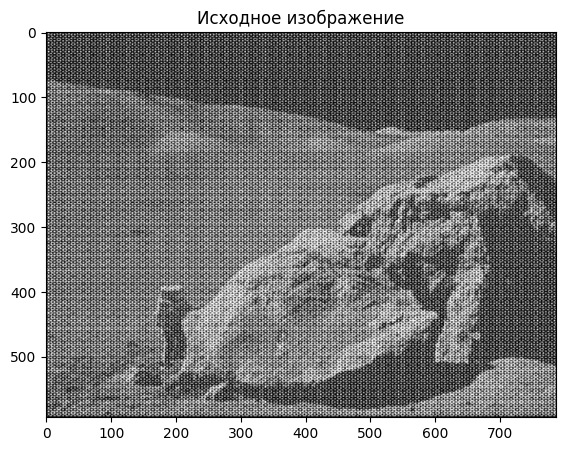

In [23]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

img_f = np.float32(img)
rows, cols = img.shape
cy, cx = rows // 2, cols // 2

plt.figure(figsize=(7, 5))
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.show()

1. Высокочастотная фильтрация на основе гауссовой маски

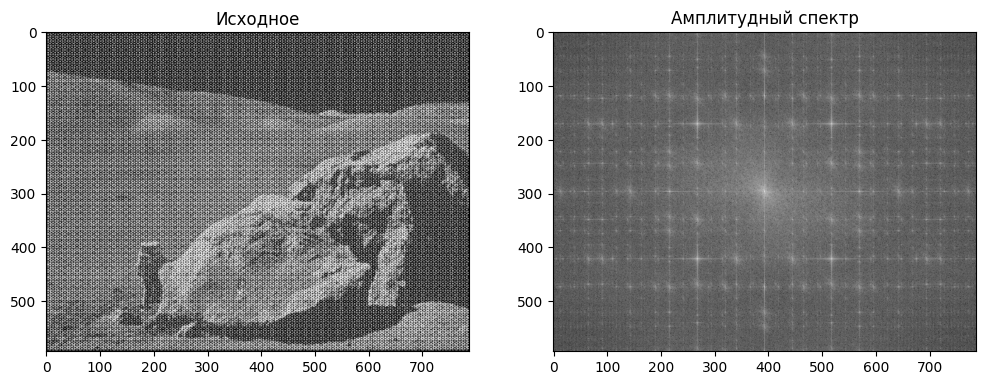

In [10]:
dft = cv.dft(img_f, flags=cv.DFT_COMPLEX_OUTPUT)
dft_centered = np.fft.fftshift(dft, axes=(0, 1))

spectrum = cv.magnitude(dft_centered[:, :, 0], dft_centered[:, :, 1])
spectrum_log = 20 * np.log(spectrum + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Исходное')
ax[1].imshow(spectrum_log, cmap='gray'); ax[1].set_title('Амплитудный спектр')
plt.show()

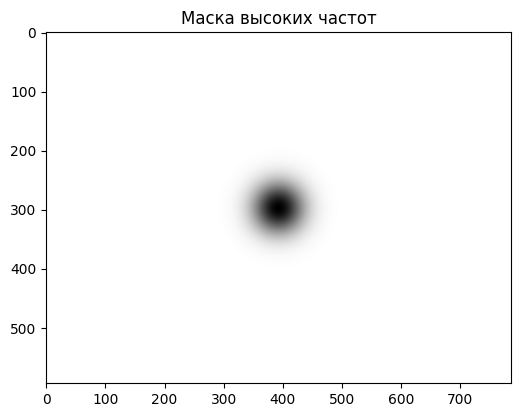

In [11]:
D0 = 30
yy, xx = np.ogrid[:rows, :cols]
dist2 = (yy - cy) ** 2 + (xx - cx) ** 2

gaussian_low = np.exp(-dist2 / (2 * D0 ** 2))
gaussian_high = 1 - gaussian_low
high_mask = np.dstack((gaussian_high, gaussian_high)).astype(np.float32)

plt.figure(figsize=(6, 5))
plt.imshow(gaussian_high, cmap='gray')
plt.title('Маска высоких частот')
plt.show()

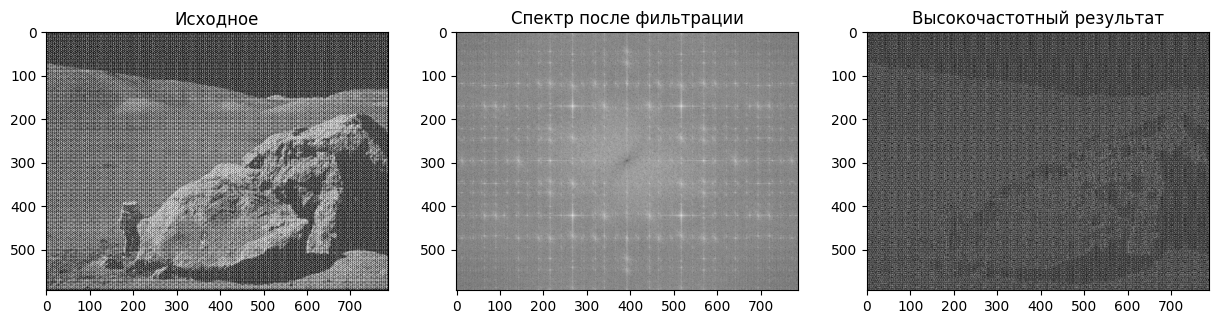

In [14]:
dft_high = dft_centered * high_mask
high_spectrum = cv.magnitude(dft_high[:, :, 0], dft_high[:, :, 1])
high_spectrum_log = 20 * np.log(high_spectrum + 1)

inverse = np.fft.ifftshift(dft_high, axes=(0, 1))
restored = cv.idft(inverse)
high_result = cv.magnitude(restored[:, :, 0], restored[:, :, 1])

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Исходное')
ax[1].imshow(high_spectrum_log, cmap='gray'); ax[1].set_title('Спектр после фильтрации')
ax[2].imshow(high_result, cmap='gray'); ax[2].set_title('Высокочастотный результат')
plt.show()

2. Вычисление свёртки с помощью преобразования Фурье

In [15]:
def fft_convolution(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape
    shape = (h + kh - 1, w + kw - 1)

    image_fft = np.fft.fft2(image.astype(np.float32), s=shape)
    kernel_fft = np.fft.fft2(kernel.astype(np.float32), s=shape)
    full_result = np.fft.ifft2(image_fft * kernel_fft).real

    y0, x0 = kh // 2, kw // 2
    return full_result[y0:y0 + h, x0:x0 + w]

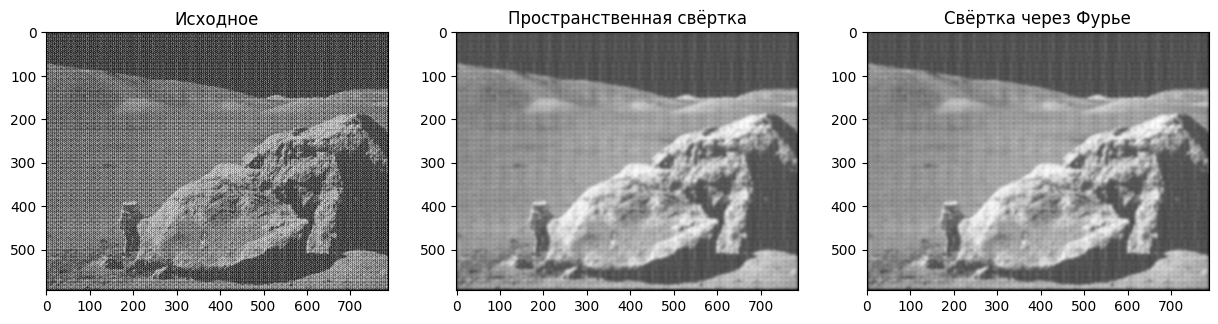

Средняя абсолютная разница: 1.3856522e-05


In [16]:
ksize = 15
sigma = 3
g = cv.getGaussianKernel(ksize, sigma)
kernel = g @ g.T

spatial_result = cv.filter2D(
    img_f, cv.CV_32F, kernel, borderType=cv.BORDER_CONSTANT
)
fourier_result = fft_convolution(img_f, kernel)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap='gray'); ax[0].set_title('Исходное')
ax[1].imshow(spatial_result, cmap='gray'); ax[1].set_title('Пространственная свёртка')
ax[2].imshow(fourier_result, cmap='gray'); ax[2].set_title('Свёртка через Фурье')
plt.show()

print('Средняя абсолютная разница:',
      np.mean(np.abs(spatial_result - fourier_result)))

3. Удаление периодического шума с помощью преобразования Фурье

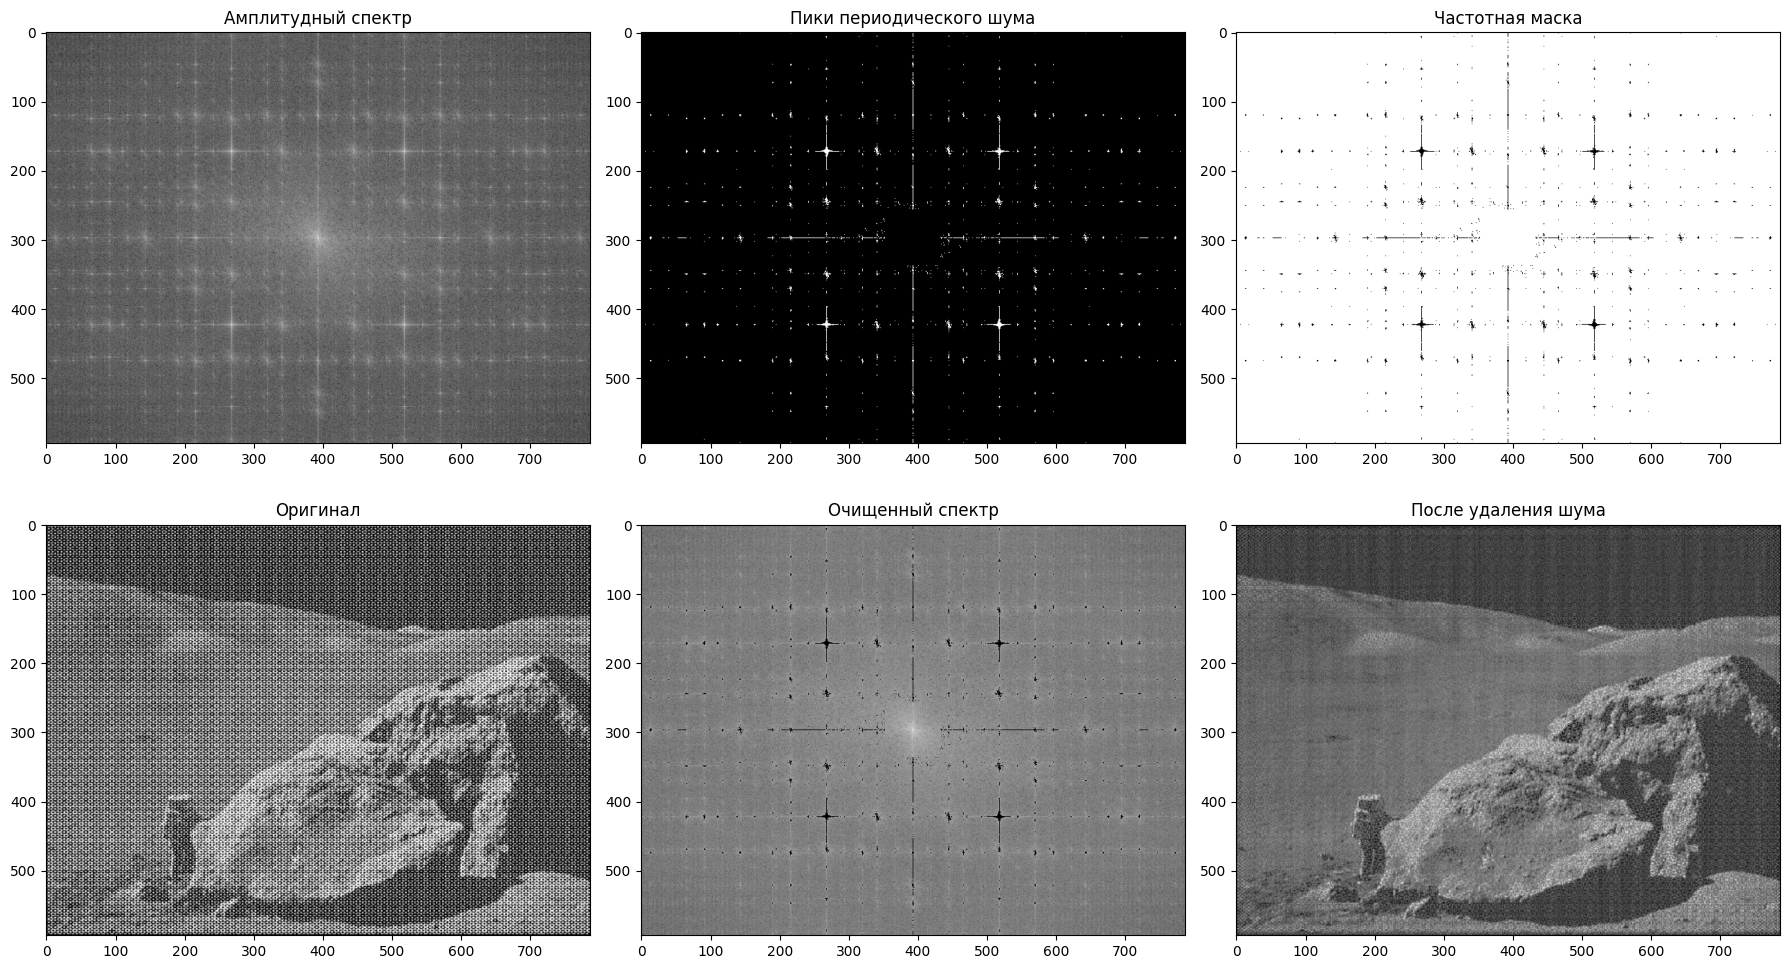

In [22]:
noise_dft = cv.dft(img_f, flags=cv.DFT_COMPLEX_OUTPUT)
noise_centered = np.fft.fftshift(noise_dft, axes=(0, 1))

amplitude = cv.magnitude(noise_centered[:, :, 0], noise_centered[:, :, 1])
amplitude_log = 20 * np.log(amplitude + 1)

spectrum_8bit = cv.normalize(
    amplitude_log, None, 0, 255, cv.NORM_MINMAX
).astype(np.uint8)

_, peaks = cv.threshold(spectrum_8bit, 140, 255, cv.THRESH_BINARY)

center_radius = 40
peaks[cy-center_radius:cy+center_radius,
      cx-center_radius:cx+center_radius] = 0

noise_mask = np.ones((rows, cols), dtype=np.float32)
noise_mask[peaks > 0] = 0
noise_mask_2ch = np.repeat(noise_mask[:, :, None], 2, axis=2)

filtered_dft = noise_centered * noise_mask_2ch
filtered_amplitude = cv.magnitude(
    filtered_dft[:, :, 0], filtered_dft[:, :, 1]
)
filtered_log = 20 * np.log(filtered_amplitude + 1)

uncentered = np.fft.ifftshift(filtered_dft, axes=(0, 1))
inverse_result = cv.idft(uncentered)
denoised = cv.magnitude(inverse_result[:, :, 0], inverse_result[:, :, 1])

fig, ax = plt.subplots(2, 3, figsize=(18, 10))

ax[0, 0].imshow(amplitude_log, cmap='gray')
ax[0, 0].set_title('Амплитудный спектр')

ax[0, 1].imshow(peaks, cmap='gray')
ax[0, 1].set_title('Пики периодического шума')

ax[0, 2].imshow(noise_mask, cmap='gray')
ax[0, 2].set_title('Частотная маска')

ax[1, 0].imshow(img, cmap='gray')
ax[1, 0].set_title('Оригинал')

ax[1, 1].imshow(filtered_log, cmap='gray')
ax[1, 1].set_title('Очищенный спектр')

ax[1, 2].imshow(denoised, cmap='gray')
ax[1, 2].set_title('После удаления шума')


plt.tight_layout()
plt.show()